# Phishing website detection lab
PRT565 Assessment 3 (group presentation). This notebook walks through the complete, reproducible experiment and shows the saved evidence used in the report and slides. Read README.md first.

**Research question:** which machine-learning or deep-learning model most reliably separates phishing websites from legitimate ones, using 30 pre-extracted indicators, when repeated inputs are prevented from leaking between training and testing?

**Models compared:** the four required models (Decision Tree, Random Forest, Categorical Naive Bayes, Multilayer ANN), four additional algorithms (Logistic Regression, k-NN, SVM, Gradient Boosting), a deeper 3-layer ANN, and two recurrent deep-learning models (LSTM, simple RNN) in `deep_learning_extension.py`.

In [1]:
from pathlib import Path
import os
import sys

# Locate the project before importing its training module.
candidates = [Path.cwd(), Path.cwd() / 'phishing_project', Path.cwd().parent]
ROOT = next((p.resolve() for p in candidates if (p / 'train.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open the extracted phishing_project folder in VS Code, '
                            'or launch this notebook with Start_Mac.command.')
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
try:
    import json
    import pandas as pd
    from IPython.display import display, Image
    from train import load_data, main
except ImportError as exc:
    raise ImportError('Select the PRT565 Phishing (.venv) kernel after running '
                      'Start_Mac.command. Missing dependency: ' + str(exc)) from exc
print('Project:', ROOT)
print('Python:', sys.executable)


Project: /home/claude/work/Final/02_Code_and_Evidence/phishing_project
Python: /home/claude/work/Final/02_Code_and_Evidence/phishing_project/.venv/bin/python


## 1. Dataset description
Each row contains encoded indicators, not a raw URL. The original target -1 becomes phishing = 1 (the positive class).

In [2]:
X, y, groups, source = load_data()
display(X.head())
display(y.value_counts().rename(index={0:"Legitimate",1:"Phishing"}))
print("Rows:", len(X), "Features:", X.shape[1], "Unique patterns:", len(set(groups)))

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,RightClick,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,1,-1,-1,-1,-1,1,1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,1,-1,-1,0,-1,1,1,1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,1,-1,1,-1,1,0,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,1,-1,-1,1,-1,1,-1,1
4,1,0,-1,1,1,-1,1,1,-1,1,...,1,-1,1,-1,-1,0,-1,1,1,1


Result
Legitimate    6157
Phishing      4898
Name: count, dtype: int64

Rows: 11055 Features: 30 Unique patterns: 5785


**Your turn:** explain why URL_Length=1 does not mean one character. Open the original feature documentation and explain two other features.

## 2. Dataset analysis (EDA)
Class balance is moderate (44% phishing), so accuracy alone is informative but precision/recall/F1 are still needed. Mutual information is computed on development rows only.

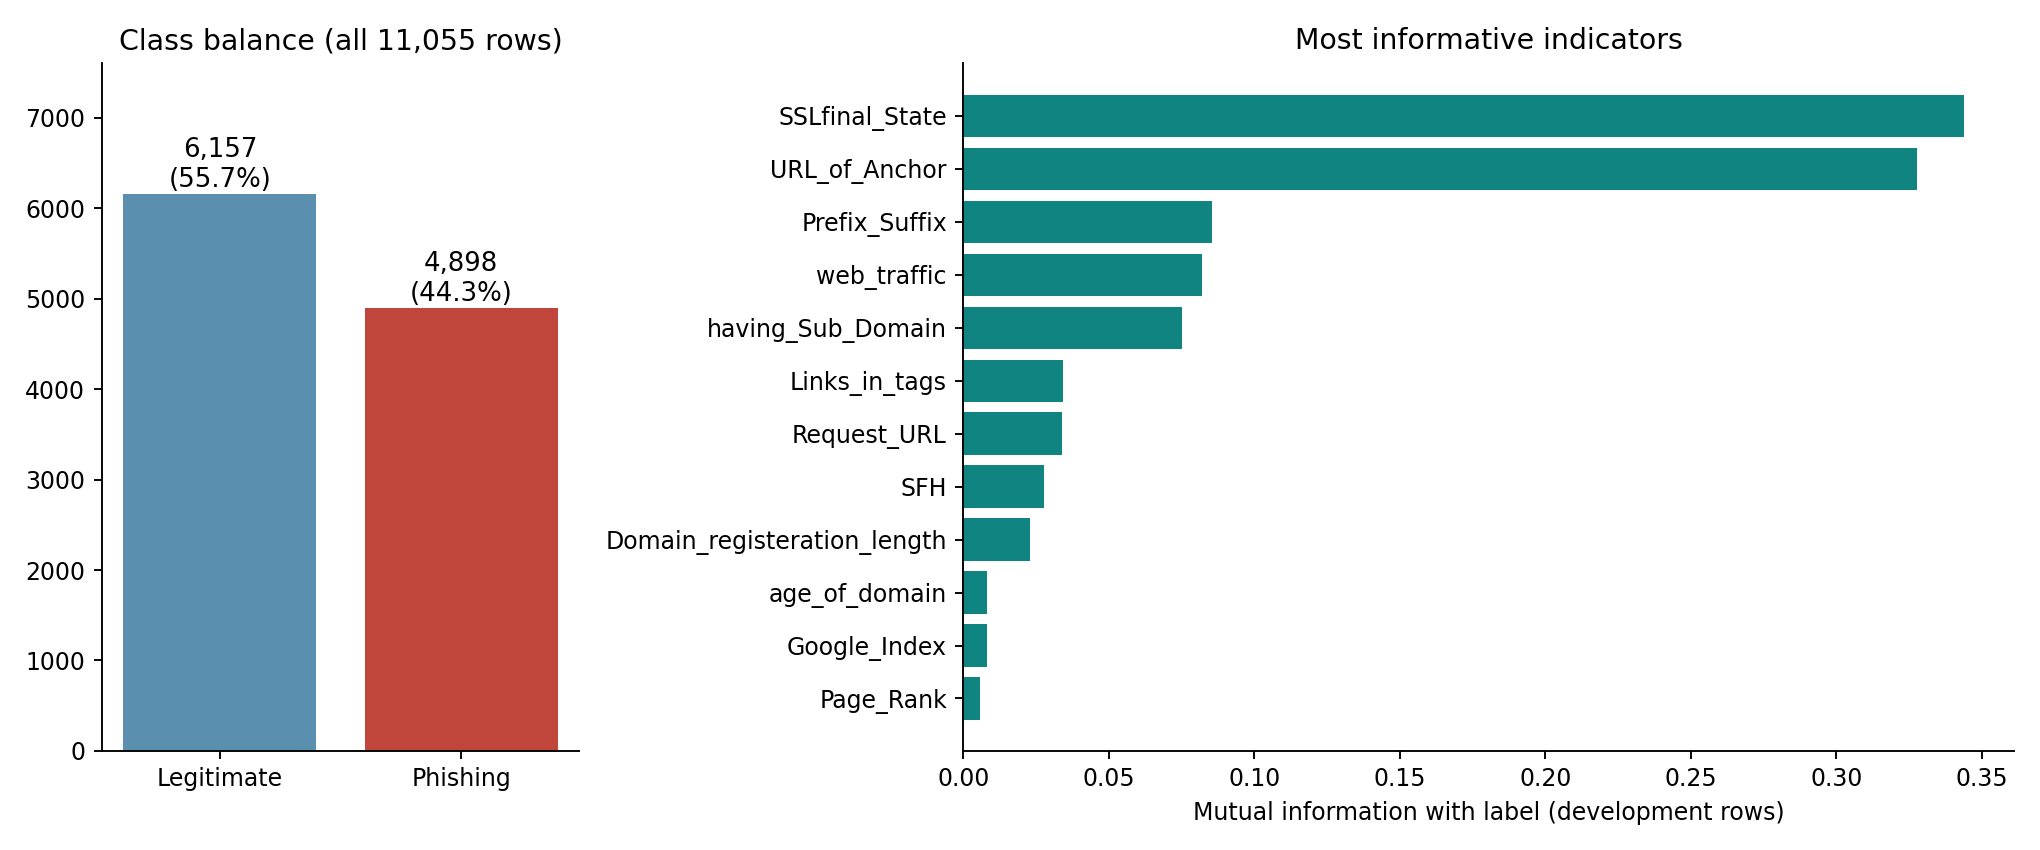

,mutual_information
SSLfinal_State,0.3440
URL_of_Anchor,0.3279
Prefix_Suffix,0.0856
web_traffic,0.0819
having_Sub_Domain,0.0750
Links_in_tags,0.0344
Request_URL,0.0340
SFH,0.0276
Domain_registeration_length,0.0230
age_of_domain,0.0082


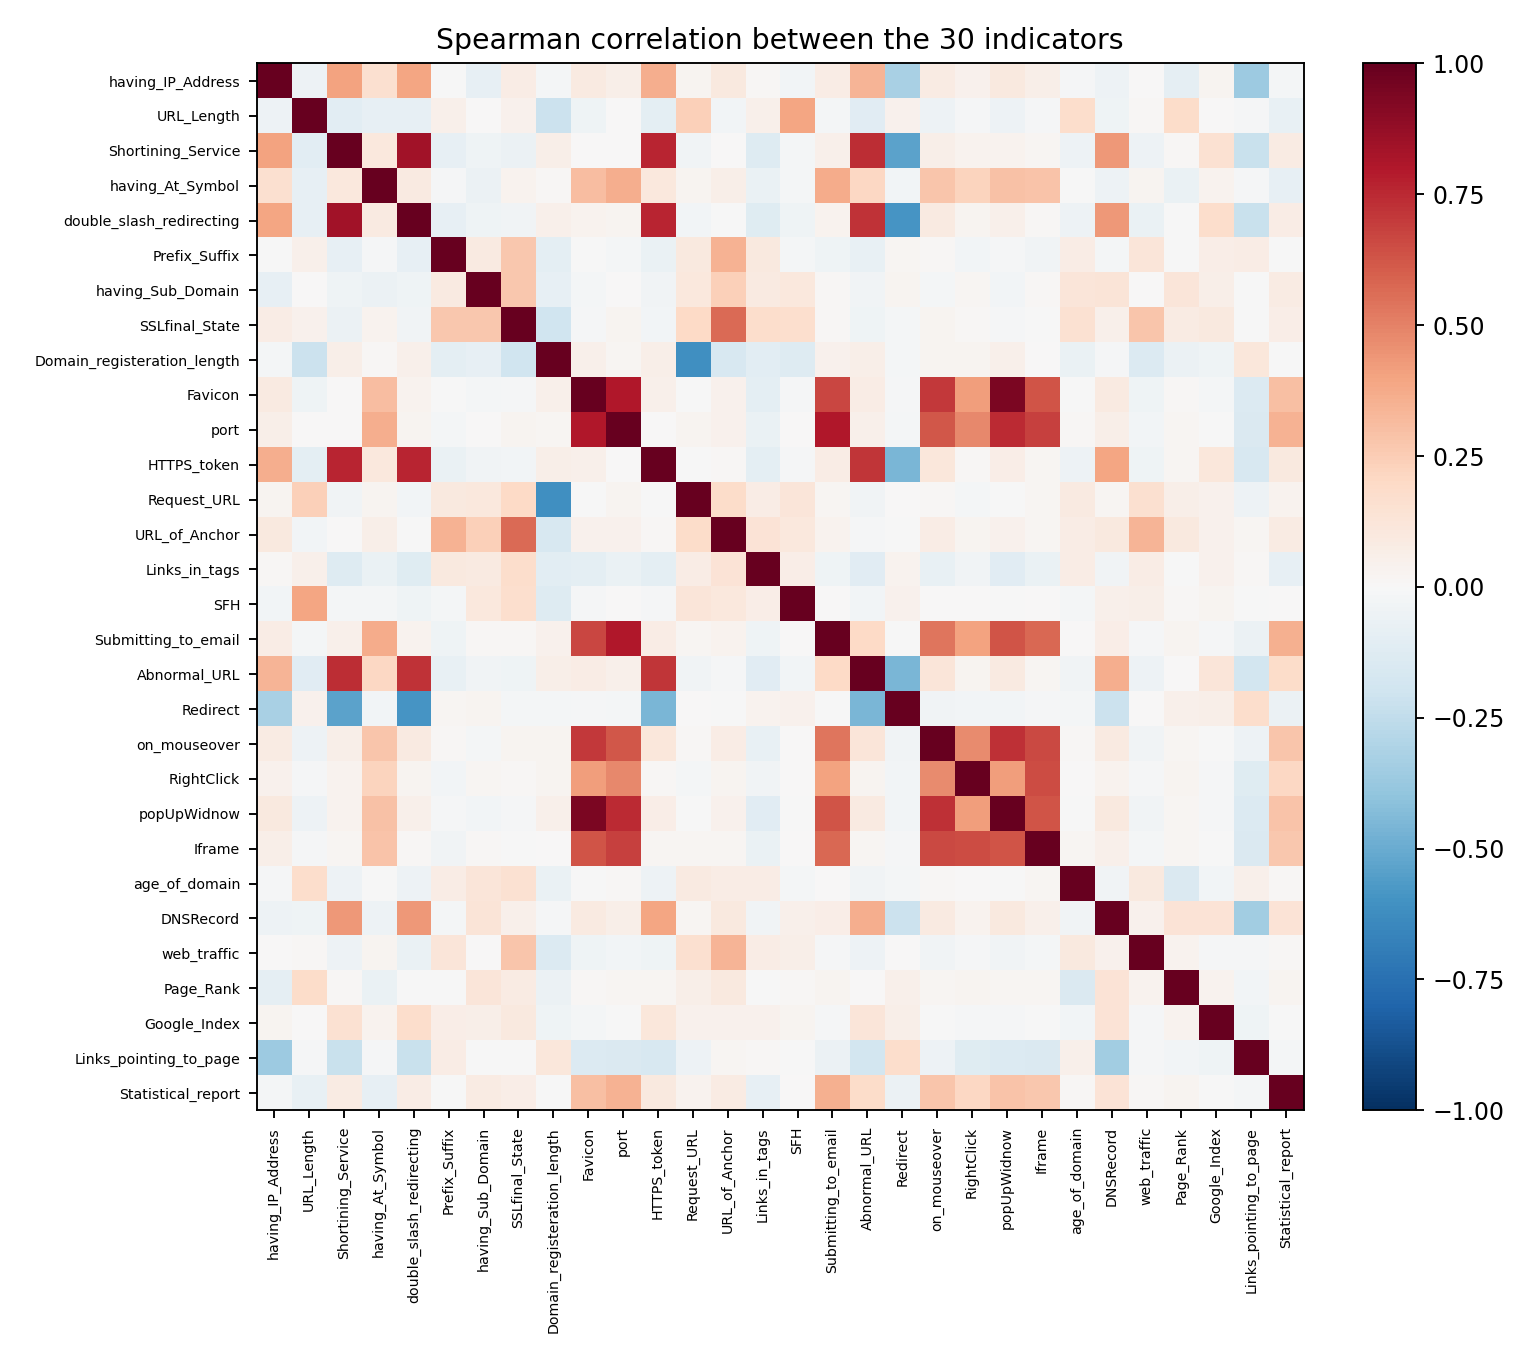

In [3]:
display(Image(filename=str(ROOT/'results/eda_overview.png')))
display(pd.read_csv(ROOT/'results/eda_mutual_information.csv', index_col=0).head(10).round(4))
display(Image(filename=str(ROOT/'results/eda_correlation.png')))

## 3. Reproduce the experiment
The saved run is already complete. Set `RUN_TRAINING=True` to regenerate `results/` with `train.py` (about 2 minutes). Set `RUN_DEEP_LEARNING=True` to also run the optional LSTM/RNN extension (requires `pip install -r requirements-deep-learning.txt`). Outputs overwrite `results/`; copy that folder first if you need the original evidence.

In [4]:
RUN_TRAINING = False
RUN_DEEP_LEARNING = False
if RUN_TRAINING:
    main()
if RUN_DEEP_LEARNING:
    import deep_learning_extension
    deep_learning_extension.main()
if not (RUN_TRAINING or RUN_DEEP_LEARNING):
    print('Exploring included benchmark outputs; training skipped.')

Exploring included benchmark outputs; training skipped.


## 4. Preprocessing, audit and group-safe split
Identical input patterns are hashed into groups so a pattern never appears on both sides of a split. Conflicting labels are kept. Every model is tuned on the SAME three grouped folds; the primary model is chosen by CV F1 before any test result is examined.

In [5]:
audit=json.loads((ROOT/"results/audit.json").read_text())
display(audit)
display(pd.read_csv(ROOT/"results/cv_summary.csv"))
manifest=pd.read_csv(ROOT/"results/split_manifest.csv")
assert manifest.groupby("group")["split"].nunique().max()==1
print("No identical feature group crosses the final split.")

{'rows': 11055,
 'features': 30,
 'missing': 0,
 'duplicate_feature_rows': 5270,
 'duplicate_full_rows': 5206,
 'unique_feature_patterns': 5785,
 'conflicting_label_patterns': 64,
 'phishing': 4898,
 'legitimate': 6157,
 'train_rows': 8845,
 'test_rows': 2210,
 'train_phishing': 3919,
 'test_phishing': 979,
 'split_seed': 565,
 'target_mapping': {'original_-1': 'phishing=1', 'original_1': 'legitimate=0'},
 'sha256_arff': '3bcf93b1612306537ee2737751f1bac185b2a77886ab376644c3bf0c7f7cb3e6'}

,model,required,cv_f1,cv_sd,train_cv_f1,search_seconds,parameters
0,Decision Tree,True,0.916869,0.008515,0.960814,0.599411,"{'model__max_depth': None, 'model__min_samples..."
1,Random Forest,True,0.945789,0.006229,0.988117,7.435728,"{'model__max_depth': None, 'model__min_samples..."
2,Categorical NB,True,0.917650,0.005455,0.920601,0.143487,{'model__alpha': 1.0}
3,Multilayer ANN,True,0.936242,0.006566,0.982915,12.855419,{'model__alpha': 0.01}
4,Logistic Regression,False,0.929918,0.006979,0.933234,0.489867,{'model__C': 10.0}
5,k-Nearest Neighbours,False,0.924727,0.006218,0.988079,5.687699,"{'model__n_neighbors': 15, 'model__weights': '..."
6,SVM (RBF),False,0.942340,0.005284,0.976875,19.525284,{'model__C': 10.0}
7,Gradient Boosting,False,0.945714,0.004866,0.980524,3.991020,"{'model__learning_rate': 0.1, 'model__max_leaf..."
8,Deep ANN (3 layers),False,0.942841,0.009606,0.987173,18.960527,{'model__alpha': 0.01}
9,Top 10 Random Forest,False,0.923662,0.009034,NaN,NaN,Fixed best full-model settings; exploratory ex...


No identical feature group crosses the final split.


## 5. Held-out test results
Phishing is the positive class. `f1_ci_low/high` is a 95% group-bootstrap confidence interval (1,000 resamples of whole input-pattern groups).

,model,accuracy,precision,recall,f1,f1_ci_low,f1_ci_high,roc_auc,TN,FP,FN,TP
0,Decision Tree,0.9303,0.9338,0.9070,0.9202,0.8973,0.9406,0.9582,1168,63,91,888
1,Random Forest,0.9638,0.9610,0.9571,0.9591,0.9432,0.9726,0.9931,1193,38,42,937
2,Categorical NB,0.9294,0.9309,0.9081,0.9193,0.8976,0.9401,0.9811,1165,66,90,889
3,Multilayer ANN,0.9439,0.9505,0.9213,0.9357,0.9149,0.9560,0.9915,1184,47,77,902
4,Logistic Regression,0.9335,0.9306,0.9183,0.9244,0.9024,0.9447,0.9861,1164,67,80,899
5,k-Nearest Neighbours,0.9398,0.9443,0.9183,0.9311,0.9119,0.9485,0.9853,1178,53,80,899
6,SVM (RBF),0.9538,0.9611,0.9336,0.9472,0.9283,0.9653,0.9917,1194,37,65,914
7,Gradient Boosting,0.9489,0.9446,0.9397,0.9421,0.9235,0.9605,0.9933,1177,54,59,920
8,Deep ANN (3 layers),0.9507,0.9718,0.9152,0.9427,0.9230,0.9612,0.9928,1205,26,83,896
9,Top 10 Random Forest,0.9416,0.9225,0.9479,0.9350,0.9159,0.9531,0.9845,1153,78,51,928


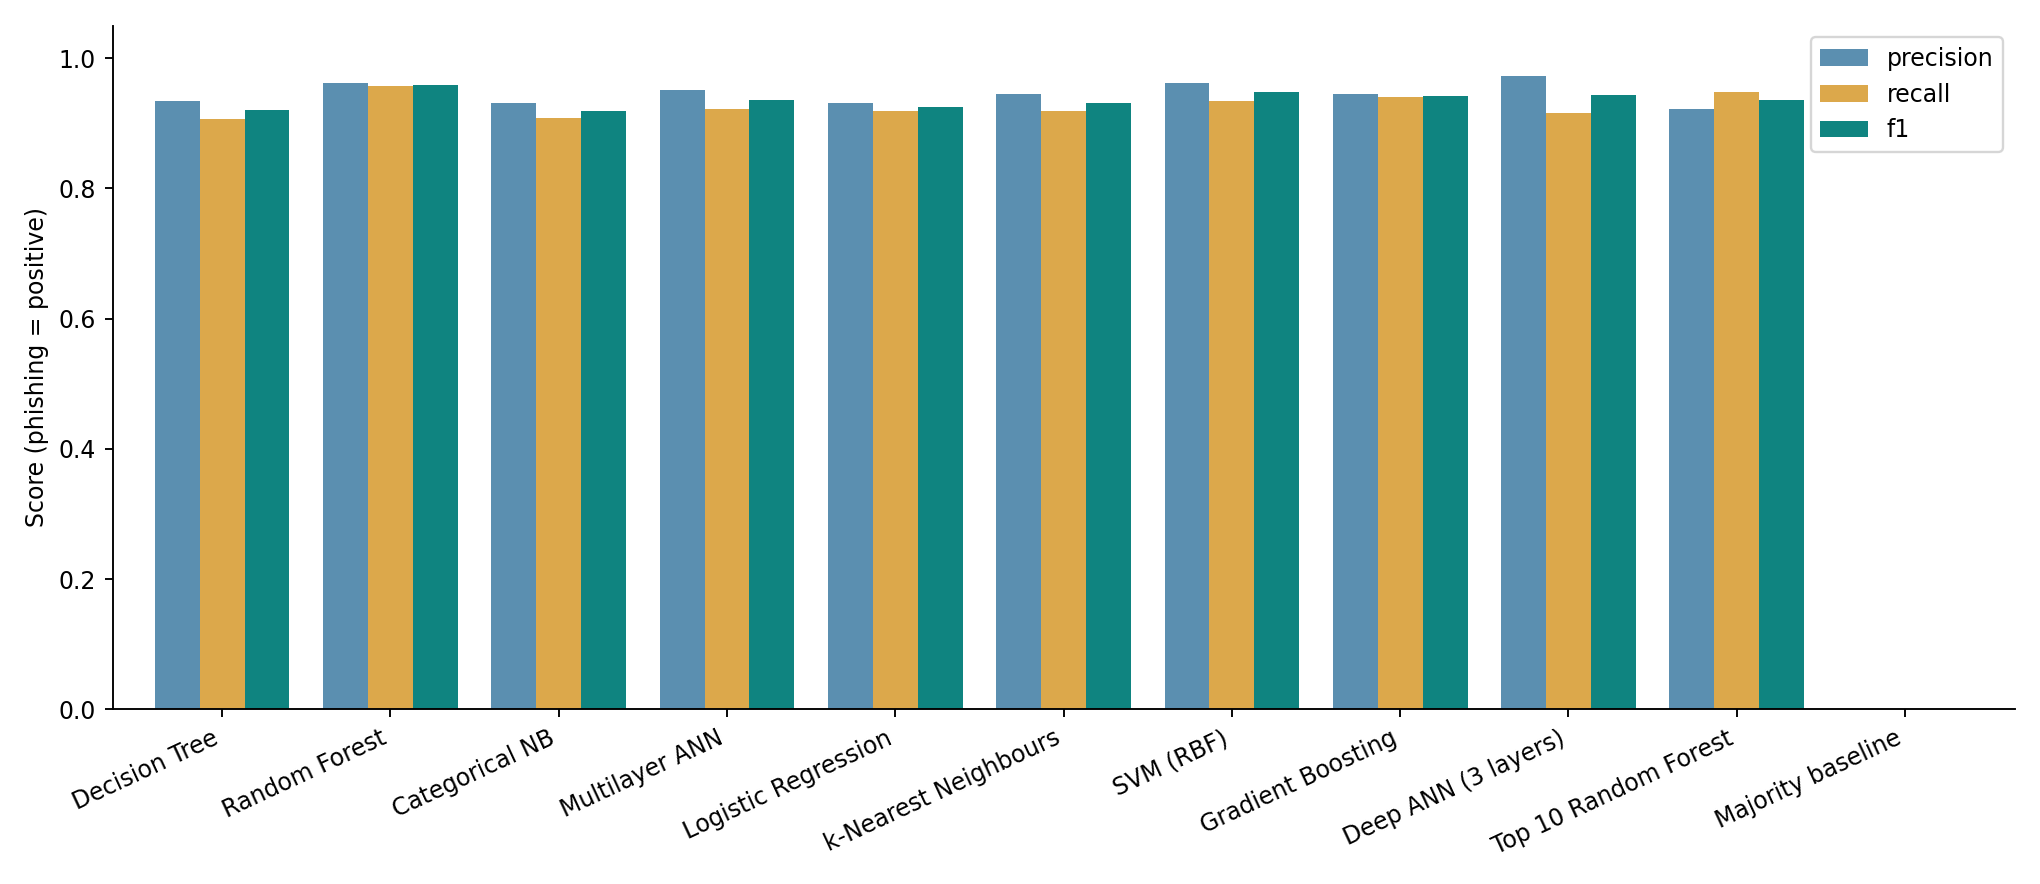

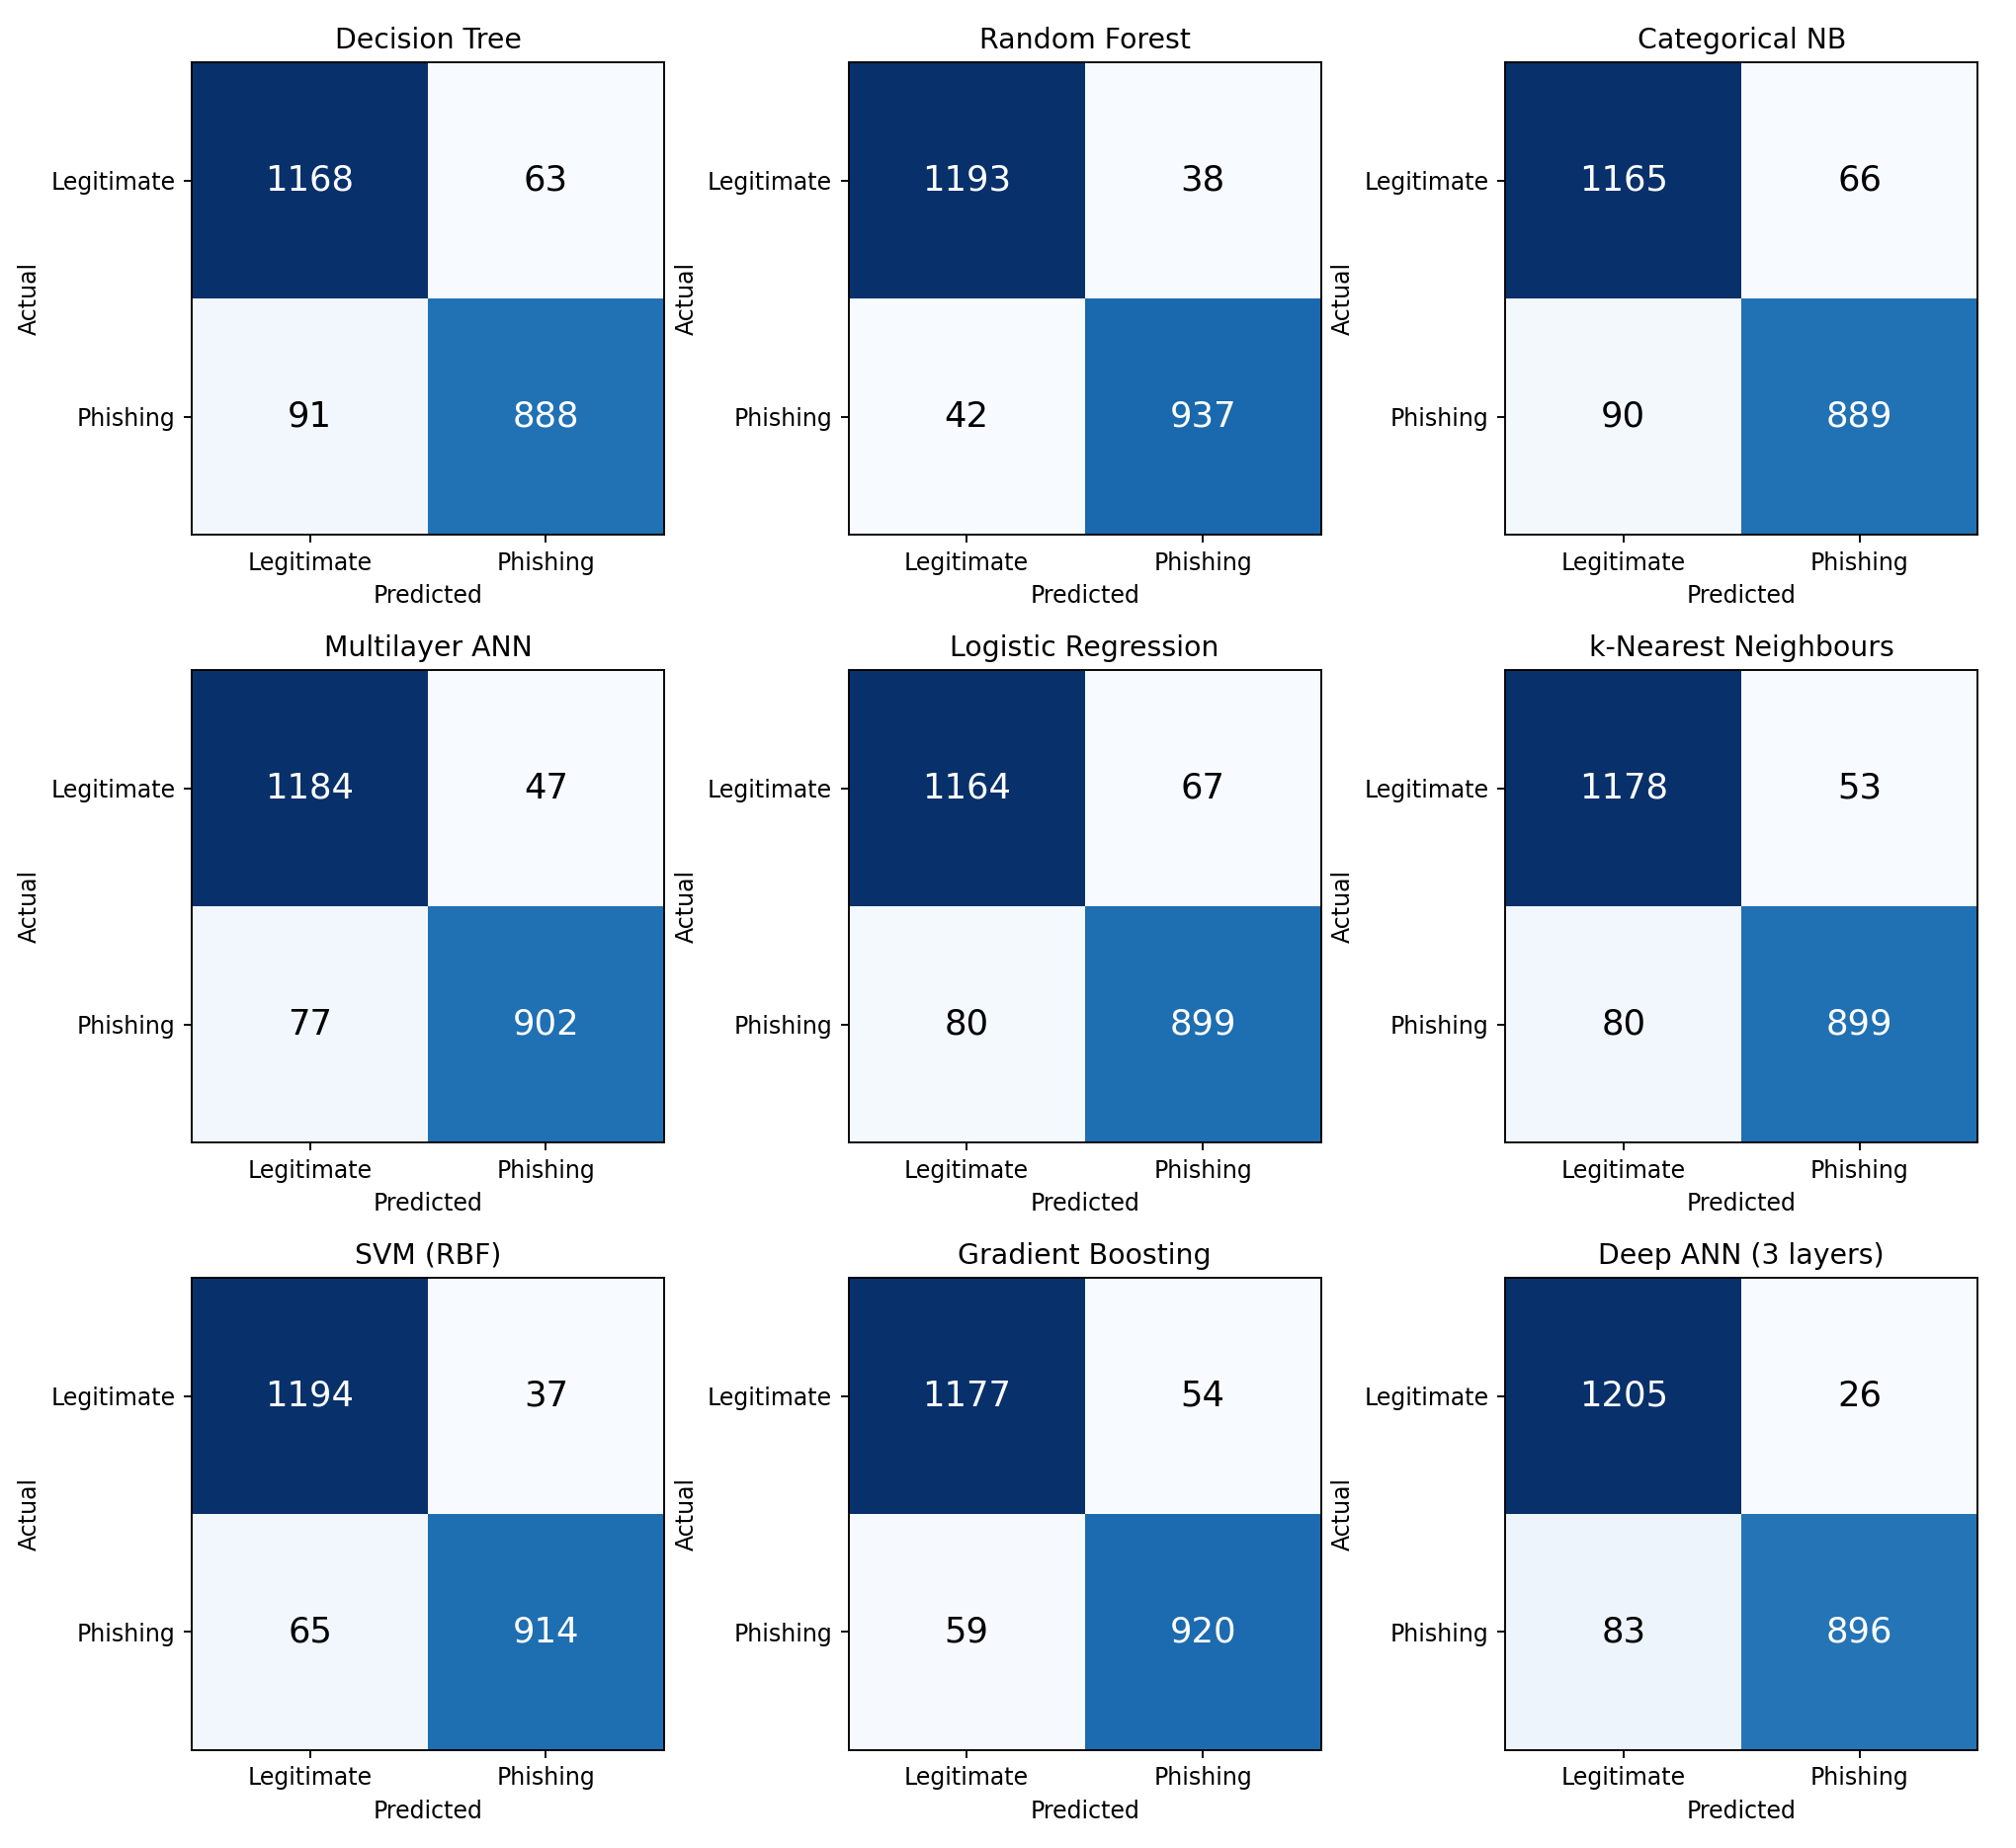

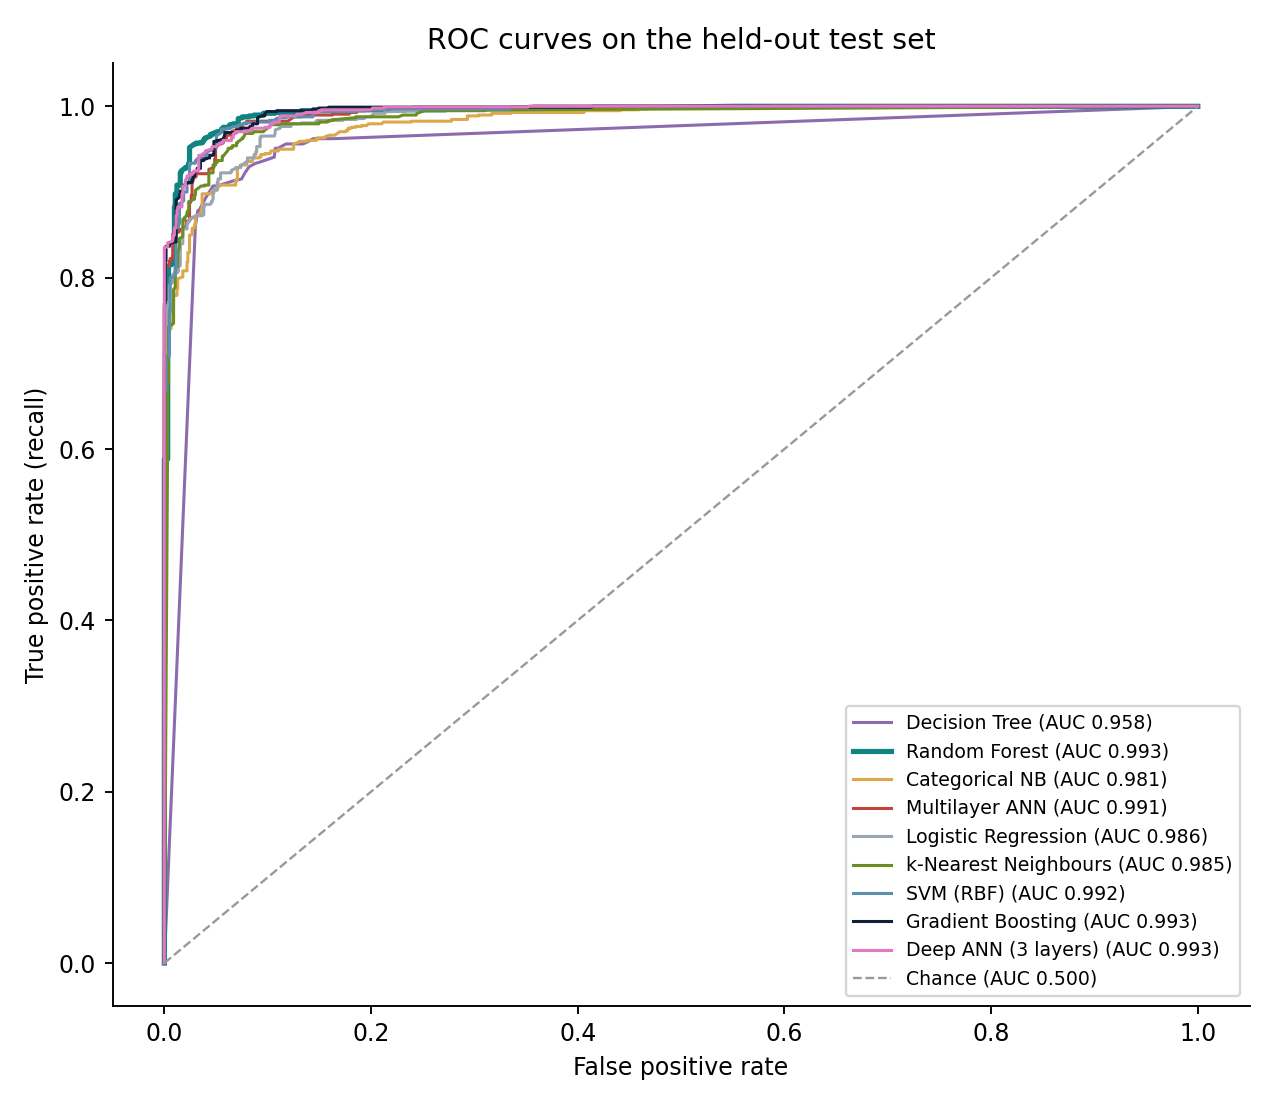

In [6]:
metrics=pd.read_csv(ROOT/'results/metrics.csv')
display(metrics.round(4))
display(Image(filename=str(ROOT/'results/model_comparison.png')))
display(Image(filename=str(ROOT/'results/confusion_matrices.png')))
display(Image(filename=str(ROOT/'results/roc_curves.png')))

**Your turn:** calculate forest precision and recall from its TP, FP and FN counts. Why does the baseline have nonzero accuracy but zero F1?

## 6. Is the winner significantly better?
Exact McNemar tests compare the Random Forest's errors with each other model on the same test rows; Holm correction controls for multiple comparisons. Caveat: repeated patterns in the test set make rows not fully independent.

In [7]:
display(pd.read_csv(ROOT/'results/significance_mcnemar.csv'))

,reference,model,reference_right_other_wrong,reference_wrong_other_right,mcnemar_exact_p,holm_adjusted_p,significant_at_0.05
0,Random Forest,Decision Tree,81,7,4.479629e-17,4.031666e-16,True
1,Random Forest,Categorical NB,88,12,1.911358e-15,1.529086e-14,True
2,Random Forest,Logistic Regression,85,18,1.363405e-11,9.543836e-11,True
3,Random Forest,k-Nearest Neighbours,68,15,3.196125e-09,1.917675e-08,True
4,Random Forest,Top 10 Random Forest,70,21,2.509087e-07,1.254543e-06,True
5,Random Forest,Multilayer ANN,63,19,1.146754e-06,4.587017e-06,True
6,Random Forest,Gradient Boosting,41,8,1.964654e-06,5.893961e-06,True
7,Random Forest,Deep ANN (3 layers),59,30,2.785269e-03,5.570538e-03,True
8,Random Forest,SVM (RBF),43,21,8.146902e-03,8.146902e-03,True


## 7. Deep learning: deeper ANN, LSTM and RNN
The loss curves show both ANNs converge. Recurrent models read the 30 indicators as a token sequence; because the column order has no temporal meaning, they are not expected to beat tree ensembles.

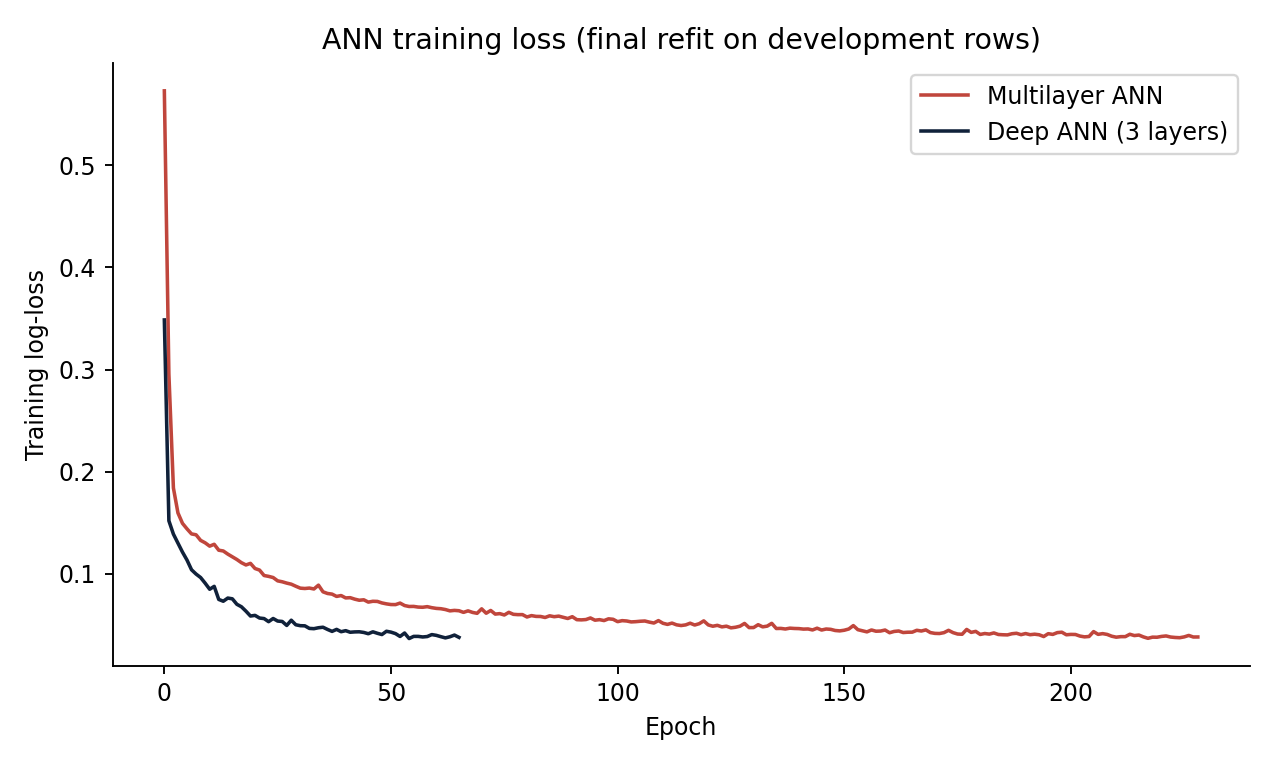

,model,cv_f1,cv_sd,epochs_per_fold,final_epochs,seconds,parameters
0,LSTM (bidirectional),0.940931,0.008131,"[37, 14, 23]",23,49.050442,"embed 16, hidden 32 x2 directions, dropout 0.2..."
1,Simple RNN (bidirectional),0.936295,0.007970,"[20, 11, 14]",14,24.878980,"embed 16, hidden 32 x2 directions, dropout 0.2..."


,model,accuracy,precision,recall,f1,f1_ci_low,f1_ci_high,roc_auc,TN,FP,FN,TP
0,LSTM (bidirectional),0.9389,0.9405,0.9203,0.9303,0.9106,0.9489,0.9889,1174,57,78,901
1,Simple RNN (bidirectional),0.9367,0.9320,0.9244,0.9282,0.9058,0.9486,0.9880,1165,66,74,905


,reference,model,reference_right_other_wrong,reference_wrong_other_right,mcnemar_exact_p
0,Random Forest,LSTM (bidirectional),69,14,6.802593e-10
1,Random Forest,Simple RNN (bidirectional),75,15,9.176485e-11


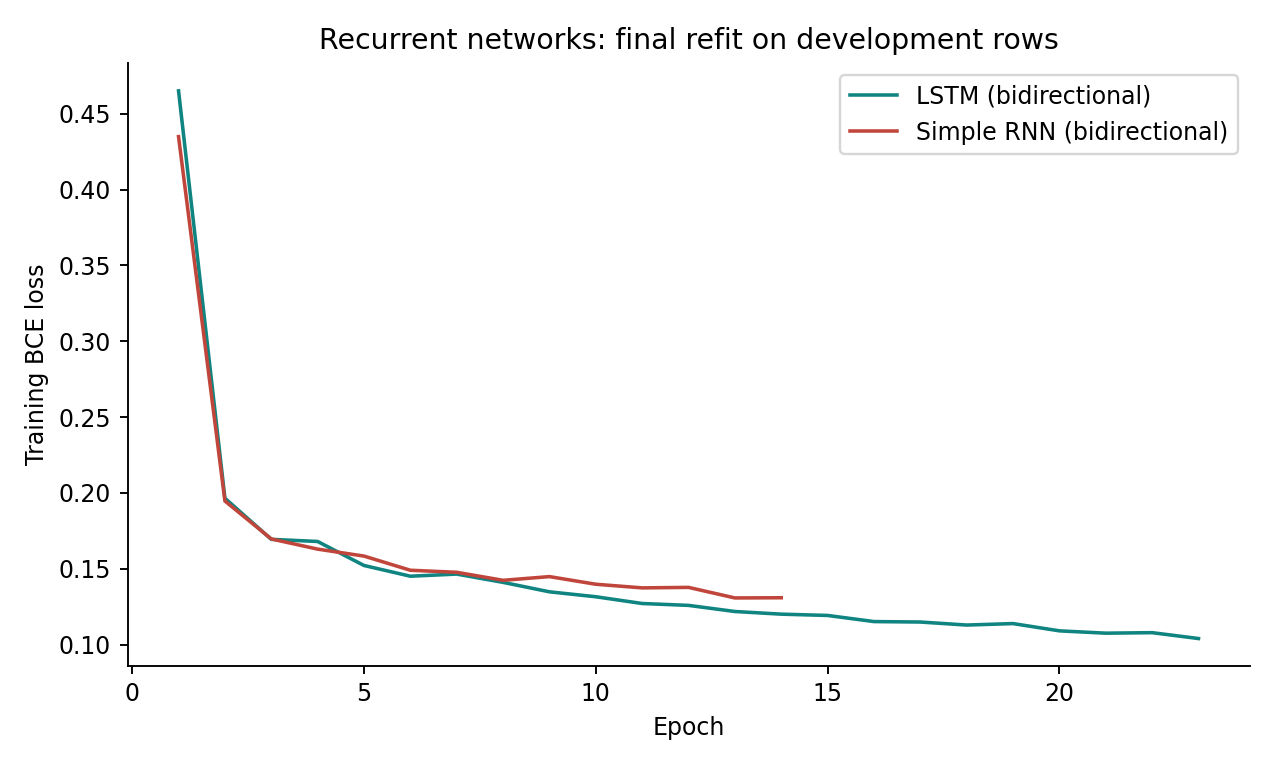

In [8]:
display(Image(filename=str(ROOT/'results/ann_loss_curves.png')))
dl=ROOT/'results/deep_learning_metrics.csv'
if dl.exists():
    display(pd.read_csv(ROOT/'results/deep_learning_cv.csv'))
    display(pd.read_csv(dl).round(4))
    display(pd.read_csv(ROOT/'results/deep_learning_mcnemar.csv'))
    display(Image(filename=str(ROOT/'results/dl_loss_curves.png')))
else:
    print('Run deep_learning_extension.py to create the LSTM/RNN results.')

## 8. Explainability and feature selection
Permutation importance: how much test F1 drops when one indicator is shuffled (explanation only, not used for selection). The top-10 mutual-information subset is an exploratory extension.

,feature,importance_mean,importance_sd
0,SSLfinal_State,0.1362,0.0045
1,URL_of_Anchor,0.1179,0.0056
2,Prefix_Suffix,0.0371,0.0052
3,web_traffic,0.0258,0.0026
4,Links_in_tags,0.0201,0.0030
5,having_Sub_Domain,0.0166,0.0030
6,Request_URL,0.0129,0.0025
7,age_of_domain,0.0121,0.0016
8,Domain_registeration_length,0.0116,0.0018
9,Links_pointing_to_page,0.0109,0.0021


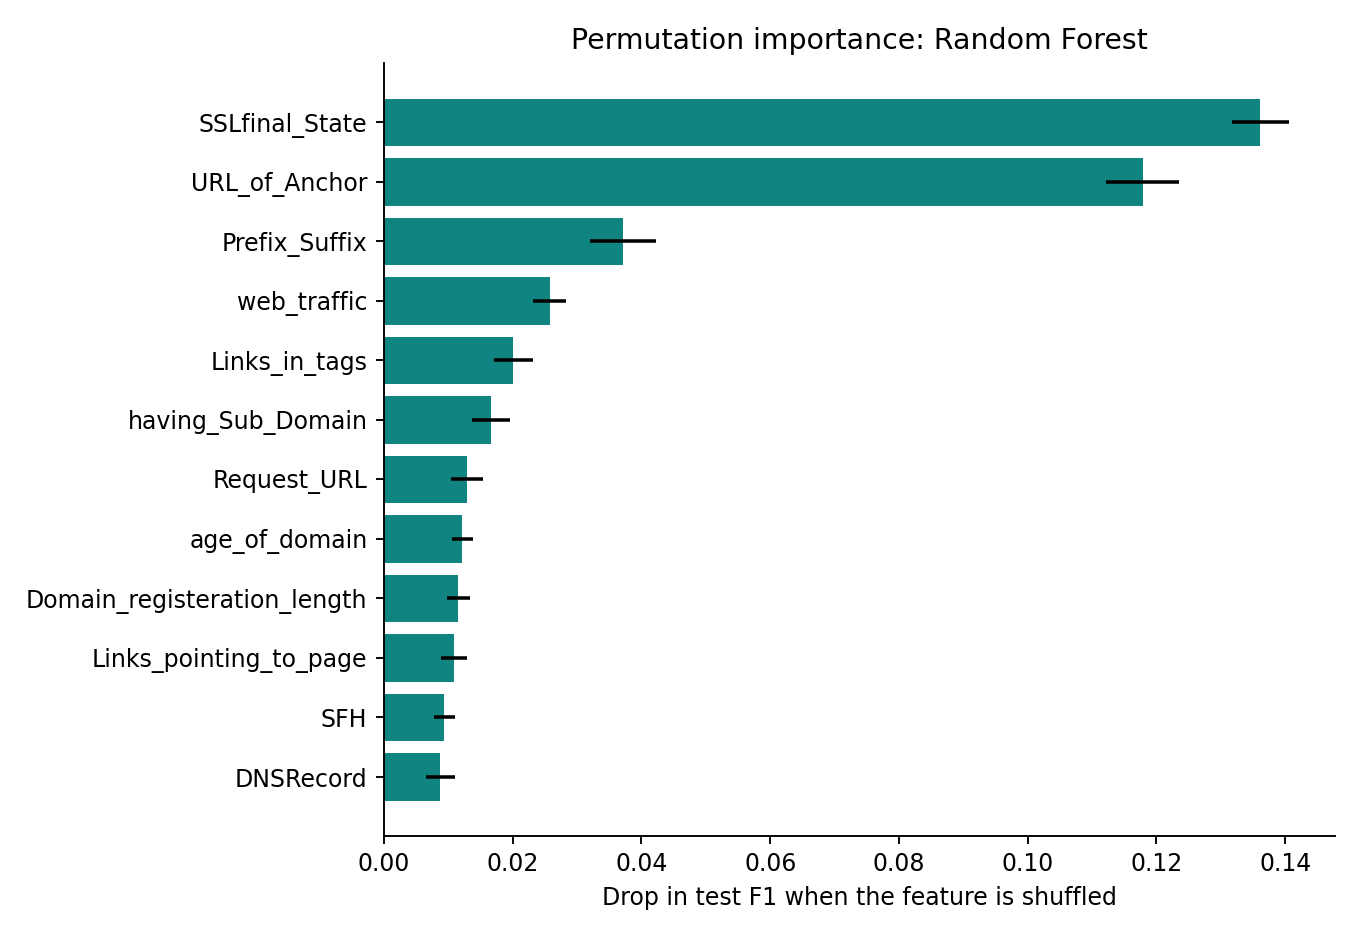

{'primary_model_selected_by_cv': 'Random Forest',
 'best_required_model_by_cv': 'Random Forest',
 'subset_base_model': 'Random Forest',
 'subset_features': ['Prefix_Suffix',
  'having_Sub_Domain',
  'SSLfinal_State',
  'Domain_registeration_length',
  'Request_URL',
  'URL_of_Anchor',
  'Links_in_tags',
  'SFH',
  'age_of_domain',
  'web_traffic'],
 'subset_cv_f1': 0.9236620132109702,
 'note': 'Selection uses development CV F1 only. No changes to models or selection after test evaluation.'}

In [9]:
display(pd.read_csv(ROOT/'results/permutation_importance.csv').head(10).round(4))
display(Image(filename=str(ROOT/'results/permutation_importance.png')))
display(json.loads((ROOT/'results/selection.json').read_text()))

## 9. Reproducible presentation demo
These are saved predictions for held-out rows, not live URL scans.

In [10]:
examples=json.loads((ROOT/"results/demo_examples.json").read_text())
for case in examples:
    print(case["case"], "row", case["row_id"], "actual", case["actual"], "predicted", case["prediction"])
    display(pd.Series(case["features"]).to_frame("encoded value"))

correct_phishing row 2 actual 1 predicted 1


,encoded value
having_IP_Address,1
URL_Length,0
Shortining_Service,1
having_At_Symbol,1
double_slash_redirecting,1
Prefix_Suffix,-1
having_Sub_Domain,-1
SSLfinal_State,-1
Domain_registeration_length,-1
Favicon,1


missed_phishing row 187 actual 1 predicted 0


,encoded value
having_IP_Address,1
URL_Length,-1
Shortining_Service,1
having_At_Symbol,1
double_slash_redirecting,1
Prefix_Suffix,-1
having_Sub_Domain,1
SSLfinal_State,1
Domain_registeration_length,1
Favicon,1


false_alarm row 212 actual 0 predicted 1


,encoded value
having_IP_Address,1
URL_Length,-1
Shortining_Service,1
having_At_Symbol,1
double_slash_redirecting,1
Prefix_Suffix,-1
having_Sub_Domain,-1
SSLfinal_State,-1
Domain_registeration_length,1
Favicon,1


## 10. Conclusion
Random Forest had the highest development CV F1 (94.58%; Gradient Boosting was effectively tied at 94.57%) and was selected before testing. On the 2,210 held-out records it reached 96.38% accuracy and 95.91% phishing F1 (95% CI 94.3–97.3%), with 42 missed phishing records and 38 false alarms. McNemar tests with Holm correction indicate its error pattern differs significantly from every other model on this test set, including the deeper ANN (94.27% F1), LSTM (93.03%) and simple RNN (92.82%).

The feature-importance analysis shows two indicators, SSLfinal_State and URL_of_Anchor, carry most of the signal, yet reducing to ten features cost 2.40 F1 points. Deep and recurrent networks did not outperform tree ensembles on these 30 categorical, non-sequential inputs, which is consistent with the tabular-data literature.

Limits: a historical 2015 dataset, pre-extracted features, no domain or time separation and a single outer split. The result supports Random Forest for this benchmark, not deployment readiness.